# EfficientNet-B0 com transfer learning

Fine-tuning completo de uma EfficientNet-B0 pré-treinada na ImageNet para as 38 classes do PlantVillage. Treinamento, checkpoint e métricas usam somente `train` e `validation`. **O conjunto de teste permanece reservado e não é iterado.**

## Caminhos e ambiente

A configuração funciona localmente e no Google Colab. No Colab, o Drive é montado e o repositório é localizado ou clonado automaticamente em `MyDrive/plant-disease-classification`, preservando dados e resultados entre sessões.

In [1]:
from pathlib import Path
import importlib.util
import subprocess
import sys

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPOSITORY_URL = 'https://github.com/murilodc/plant-disease-classification.git'
COLAB_PROJECT_DIR = Path('/content/plant-disease-classification')
LEGACY_COLAB_PROJECT_DIR = Path('/content/tcc-plant-disease-classification')
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/plant-disease-classification')
LEGACY_DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/TCC')
AUTO_CLONE_REPOSITORY = True
MOUNT_DRIVE = True
if IN_COLAB and MOUNT_DRIVE:
    drive.mount('/content/drive')


def is_project_root(path: Path) -> bool:
    return (path / 'src' / 'train_efficientnet_b0.py').is_file()


def find_project_root() -> Path:
    current = Path.cwd().resolve()
    candidates = [current, *current.parents]
    if IN_COLAB:
        candidates.extend([
            DRIVE_PROJECT_DIR, LEGACY_DRIVE_PROJECT_DIR,
            COLAB_PROJECT_DIR, LEGACY_COLAB_PROJECT_DIR,
        ])
    for candidate in candidates:
        if is_project_root(candidate):
            return candidate

    if IN_COLAB and AUTO_CLONE_REPOSITORY:
        clone_target = DRIVE_PROJECT_DIR if MOUNT_DRIVE else COLAB_PROJECT_DIR
        if clone_target.exists():
            raise FileNotFoundError(
                f'{clone_target} já existe, mas não contém o projeto completo. '
                'Remova ou renomeie esse diretório e execute a célula novamente.'
            )
        print('Clonando o repositório para o Colab...')
        subprocess.check_call([
            'git', 'clone', '--depth', '1', REPOSITORY_URL, str(clone_target)
        ])
        if is_project_root(clone_target):
            return clone_target

    raise FileNotFoundError(
        'Projeto não encontrado. Envie o repositório completo, monte o Drive '
        'ou habilite AUTO_CLONE_REPOSITORY.'
    )

BASE_DIR = find_project_root()
DATA_DIR = BASE_DIR / 'data'
RESULTS_DIR = BASE_DIR / 'results'
EFFICIENTNET_RESULTS_DIR = RESULTS_DIR / 'efficientnet_b0'
SRC_DIR = BASE_DIR / 'src'
ZIP_PATH = DATA_DIR / 'data.zip'
LEAF_MAP_PATH = DATA_DIR / 'leaf_grouping' / 'leaf-map.json'
RAW_METADATA_CSV = RESULTS_DIR / 'plantvillage_metadata_raw_color.csv'
METADATA_CSV = RESULTS_DIR / 'plantvillage_metadata_split.csv'
IMAGE_ROOT = Path('/content/plantvillage_color') if IN_COLAB else DATA_DIR / 'plantvillage_color'

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
EFFICIENTNET_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
if not SRC_DIR.exists():
    raise FileNotFoundError(f'Diretório src não encontrado: {SRC_DIR}')
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print('Base:', BASE_DIR)
print('Resultados da EfficientNet-B0:', EFFICIENTNET_RESULTS_DIR)
print('Imagens:', IMAGE_ROOT)

Mounted at /content/drive
Base: /content/drive/MyDrive/plant-disease-classification
Resultados da EfficientNet-B0: /content/drive/MyDrive/plant-disease-classification/results/efficientnet_b0
Imagens: /content/plantvillage_color


## Dependências

In [2]:
required_packages = {
    'torch': 'torch',
    'torchvision': 'torchvision',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'sklearn': 'scikit-learn',
}
missing_packages = [
    package for module_name, package in required_packages.items()
    if importlib.util.find_spec(module_name) is None
]
if missing_packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing_packages])

import json
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image, display

## Protocolo experimental

In [3]:
SEED = 42
NUM_CLASSES = 38
BATCH_SIZE = 32
MAX_EPOCHS = 30
LEARNING_RATE = 1e-4
EARLY_STOPPING_PATIENCE = 5
MIN_DELTA = 1e-4
NUM_WORKERS = 2 if IN_COLAB else 0
REQUIRE_CUDA_IN_COLAB = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if IN_COLAB and REQUIRE_CUDA_IN_COLAB and device.type != 'cuda':
    raise RuntimeError(
        'GPU não disponível. No Colab, selecione Ambiente de execução > '
        'Alterar tipo de ambiente de execução > T4 GPU e execute novamente.'
    )
print('Dispositivo selecionado automaticamente:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

Dispositivo selecionado automaticamente: cuda
GPU: NVIDIA L4


In [4]:
from efficientnet_b0_model import (
    DEFAULT_WEIGHTS,
    create_efficientnet_b0,
    efficientnet_b0_weights_name,
    validate_efficientnet_b0_preprocessing,
)
from plantvillage_audit import build_metadata_dataframe, save_metadata_csv
from plantvillage_pytorch import build_image_transforms, extract_raw_color_from_zip
from plantvillage_split import save_split_metadata_csv, split_metadata_by_leaf_id
from train_efficientnet_b0 import train_efficientnet_b0

## Dados e splits existentes

As rotinas são as mesmas dos modelos anteriores. O CSV de split existente é reutilizado sem alterações.

In [5]:
DOWNLOAD_DATA_IF_MISSING = True
EXTRACT_IMAGES_IF_MISSING = True

if DOWNLOAD_DATA_IF_MISSING and (not ZIP_PATH.exists() or not LEAF_MAP_PATH.exists()):
    if importlib.util.find_spec('huggingface_hub') is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'huggingface_hub'])
    from huggingface_hub import hf_hub_download
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    if not ZIP_PATH.exists():
        ZIP_PATH = Path(hf_hub_download(
            repo_id='mohanty/PlantVillage', filename='data.zip',
            repo_type='dataset', local_dir=str(DATA_DIR),
        ))
    if not LEAF_MAP_PATH.exists():
        LEAF_MAP_PATH = Path(hf_hub_download(
            repo_id='mohanty/PlantVillage', filename='leaf_grouping/leaf-map.json',
            repo_type='dataset', local_dir=str(DATA_DIR),
        ))

if not METADATA_CSV.exists():
    if not ZIP_PATH.exists() or not LEAF_MAP_PATH.exists():
        raise FileNotFoundError('Arquivos necessários para gerar os splits não encontrados.')
    metadata = build_metadata_dataframe(ZIP_PATH, LEAF_MAP_PATH)
    save_metadata_csv(metadata, RAW_METADATA_CSV)
    metadata_split = split_metadata_by_leaf_id(metadata)
    save_split_metadata_csv(metadata_split, METADATA_CSV)
else:
    print('CSV de split existente reutilizado:', METADATA_CSV)

if EXTRACT_IMAGES_IF_MISSING:
    if not ZIP_PATH.exists():
        raise FileNotFoundError(f'ZIP do PlantVillage não encontrado: {ZIP_PATH}')
    extraction = extract_raw_color_from_zip(ZIP_PATH, IMAGE_ROOT)
    print('Extração:', extraction)
    if int(extraction['total']) != 54_305:
        raise RuntimeError('Extração incompleta: esperadas 54.305 imagens raw/color.')
elif not IMAGE_ROOT.is_dir() or not any(IMAGE_ROOT.iterdir()):
    raise FileNotFoundError(f'Diretório de imagens vazio ou ausente: {IMAGE_ROOT}')

CSV de split existente reutilizado: /content/drive/MyDrive/plant-disease-classification/results/plantvillage_metadata_split.csv
Extração: {'output_dir': '/content/plantvillage_color', 'extracted': 54305, 'skipped': 0, 'total': 54305}


## Conferência do protocolo e preprocessing

A contagem consulta somente os metadados; nenhuma imagem de teste é carregada. A rotina comprova que a normalização compartilhada é compatível com os pesos da EfficientNet-B0 e registra o preset oficial como referência.

In [6]:
metadata_df = pd.read_csv(METADATA_CSV)
required_columns = {'zip_path', 'classe', 'leaf_id', 'split'}
missing_columns = sorted(required_columns - set(metadata_df.columns))
if missing_columns:
    raise KeyError(f'Colunas ausentes no CSV de split: {missing_columns}')
expected_split_sizes = {'train': 38_008, 'validation': 8_172, 'test': 8_125}
actual_split_sizes = metadata_df['split'].value_counts().to_dict()
if actual_split_sizes != expected_split_sizes:
    raise ValueError(f'Tamanhos de split inesperados: {actual_split_sizes}')
if metadata_df['classe'].nunique() != 38:
    raise ValueError('O CSV de split deve conter exatamente 38 classes.')
if metadata_df.groupby('leaf_id')['split'].nunique().max() != 1:
    raise ValueError('Data leakage: há leaf_id presente em mais de um split.')
split_sizes = metadata_df['split'].value_counts().rename_axis('split').reset_index(name='num_images')
display(split_sizes)

preprocessing = validate_efficientnet_b0_preprocessing(DEFAULT_WEIGHTS)
print('Pesos:', efficientnet_b0_weights_name(DEFAULT_WEIGHTS))
print('Tamanho aplicado:', (224, 224))
print('Compatibilidade e preset de referência:', preprocessing)
print('Transform de treino:', build_image_transforms('train'))
print('Transform de validação:', build_image_transforms('validation'))
print('Split usado nesta etapa: validation')
print('Split reservado: test (DataLoader não iterado)')

,split,num_images
0,train,38008
1,validation,8172
2,test,8125


Pesos: EfficientNet_B0_Weights.IMAGENET1K_V1
Tamanho aplicado: (224, 224)
Compatibilidade e preset de referência: {'normalization_source': 'EfficientNet_B0_Weights.IMAGENET1K_V1', 'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225], 'compatible_with_shared_pipeline': True, 'augmentation_policy': 'same_as_baseline_resnet50_and_densenet201', 'applied_resize': [224, 224], 'official_weights_preset_geometry_applied': False, 'geometry_decision_rationale': 'shared_224x224_pipeline_preserved_for_experimental_consistency', 'weights_preset_reference': {'crop_size': [224], 'resize_size': [256], 'interpolation': 'InterpolationMode.BICUBIC'}}
Transform de treino: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=(

## Verificação do modelo pré-treinado

O Dropout original é preservado e somente `classifier[1]` é substituída. Todos os parâmetros permanecem treináveis.

In [7]:
preview_model = create_efficientnet_b0(num_classes=NUM_CLASSES)
total_parameters = sum(parameter.numel() for parameter in preview_model.parameters())
trainable_parameters = sum(
    parameter.numel() for parameter in preview_model.parameters() if parameter.requires_grad
)
print('Classe:', type(preview_model).__name__)
print('Classifier:', preview_model.classifier)
print('Parâmetros totais:', f'{total_parameters:,}')
print('Parâmetros treináveis:', f'{trainable_parameters:,}')
assert preview_model.classifier[0].p == 0.2
assert preview_model.classifier[1].out_features == NUM_CLASSES
assert total_parameters == trainable_parameters
del preview_model

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 124MB/s] 


Classe: EfficientNet
Classifier: Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=38, bias=True)
)
Parâmetros totais: 4,056,226
Parâmetros treináveis: 4,056,226


## Treinamento e avaliação na validação

A execução manual usa Adam, `CrossEntropyLoss`, learning rate `1e-4`, até 30 épocas e early stopping por `validation_loss`. O melhor checkpoint é restaurado antes da inferência.

In [8]:
model, history, checkpoint_path = train_efficientnet_b0(
    metadata_csv=METADATA_CSV,
    image_root=IMAGE_ROOT,
    output_dir=EFFICIENTNET_RESULTS_DIR,
    batch_size=BATCH_SIZE,
    epochs=MAX_EPOCHS,
    learning_rate=LEARNING_RATE,
    num_classes=NUM_CLASSES,
    num_workers=NUM_WORKERS,
    seed=SEED,
    patience=EARLY_STOPPING_PATIENCE,
    min_delta=MIN_DELTA,
)
print('Melhor checkpoint restaurado:', checkpoint_path)

Device: cuda
EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv

## Arquitetura e complexidade

In [9]:
with (EFFICIENTNET_RESULTS_DIR / 'architecture_summary.json').open(encoding='utf-8') as file:
    architecture = json.load(file)
display(pd.Series({
    'model_class': architecture['model_class'],
    'architecture': architecture['architecture'],
    'pretrained_weights': architecture['pretrained_weights'],
    'total_parameters': architecture['total_parameters'],
    'trainable_parameters': architecture['trainable_parameters'],
    'final_layer_in_features': architecture['final_layer_in_features'],
    'num_output_classes': architecture['num_output_classes'],
    'dropout': architecture['classifier_dropout']['p'],
}, name='architecture').to_frame())
display(pd.DataFrame(architecture['main_blocks']['mbconv_stages']))

,architecture
model_class,EfficientNet
architecture,EfficientNet-B0
pretrained_weights,EfficientNet_B0_Weights.IMAGENET1K_V1
total_parameters,4056226
trainable_parameters,4056226
final_layer_in_features,1280
num_output_classes,38
dropout,0.2


,name,block_type,num_blocks,output_channels,kernel_size,first_block_stride,expansion_ratio
0,features.1,MBConv,1,16,3,1,1
1,features.2,MBConv,2,24,3,2,6
2,features.3,MBConv,2,40,5,2,6
3,features.4,MBConv,3,80,3,2,6
4,features.5,MBConv,3,112,5,1,6
5,features.6,MBConv,4,192,5,2,6
6,features.7,MBConv,1,320,3,1,6


## Histórico, curvas e tempos

,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,epoch_time_seconds
0,1,0.443190,0.902073,0.047760,0.986295,116.089736
1,2,0.048612,0.986161,0.034121,0.990455,114.853594
2,3,0.029750,0.991291,0.035635,0.989599,115.149633
3,4,0.022905,0.992686,0.032901,0.990945,115.082606
4,5,0.018349,0.993975,0.026701,0.992658,115.434234
5,6,0.015575,0.995106,0.025516,0.993147,115.080402
6,7,0.012382,0.996369,0.033656,0.991679,114.991650
7,8,0.012180,0.996317,0.026763,0.993392,115.346403
8,9,0.008641,0.997606,0.026039,0.993514,114.920554
9,10,0.010006,0.996764,0.025104,0.994004,114.916096


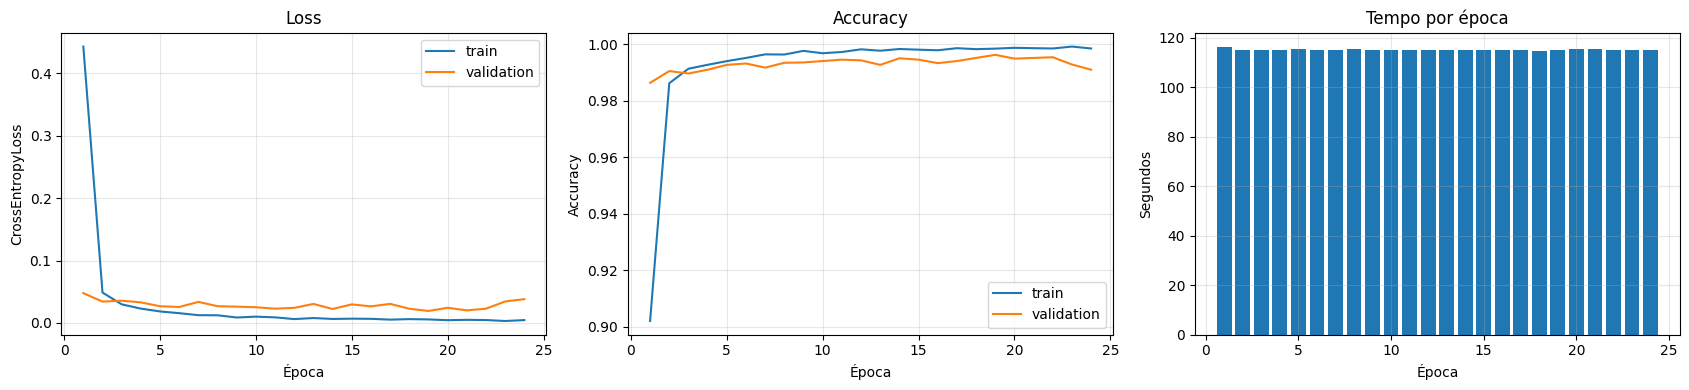

,training
epochs,24
total_time_seconds,2761.284244
average_time_per_epoch_seconds,115.05351
measurement_scope,sum_of_epoch_train_and_validation_passes
epochs_executed,24
best_epoch,19
best_validation_loss,0.019138
stopped_epoch,24
early_stopping,True


,validation_inference
total_time_seconds,11.259341
average_time_per_image_seconds,0.001378
throughput_images_per_second,725.797374
num_images,8172
warmup_batches,1
measurement_scope,end_to_end_dataloader


In [10]:
history_df = pd.DataFrame(history)
display(history_df)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(history_df['epoch'], history_df['train_loss'], label='train')
axes[0].plot(history_df['epoch'], history_df['validation_loss'], label='validation')
axes[0].set(title='Loss', xlabel='Época', ylabel='CrossEntropyLoss')
axes[0].legend()
axes[1].plot(history_df['epoch'], history_df['train_accuracy'], label='train')
axes[1].plot(history_df['epoch'], history_df['validation_accuracy'], label='validation')
axes[1].set(title='Accuracy', xlabel='Época', ylabel='Accuracy')
axes[1].legend()
axes[2].bar(history_df['epoch'], history_df['epoch_time_seconds'])
axes[2].set(title='Tempo por época', xlabel='Época', ylabel='Segundos')
for axis in axes:
    axis.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

with (EFFICIENTNET_RESULTS_DIR / 'timing_summary.json').open(encoding='utf-8') as file:
    timing_summary = json.load(file)
display(pd.Series(timing_summary['training'], name='training').to_frame())
display(pd.Series(timing_summary['validation_inference'], name='validation_inference').to_frame())

## Métricas gerais e por classe

In [11]:
validation_metrics_df = pd.read_csv(EFFICIENTNET_RESULTS_DIR / 'validation_metrics.csv')
class_metrics_df = pd.read_csv(EFFICIENTNET_RESULTS_DIR / 'validation_metrics_by_class.csv')
display(validation_metrics_df.T.rename(columns={0: 'value'}))
display(class_metrics_df)

,value
accuracy,0.996207
precision_macro,0.992885
recall_macro,0.994838
f1_macro,0.993820
precision_weighted,0.996247
recall_weighted,0.996207
f1_weighted,0.996212
num_samples,8172.000000
num_classes,38.000000


,class_index,class_name,precision,recall,f1_score,support
0,0,Apple___Apple_scab,0.979167,0.989474,0.984293,95
1,1,Apple___Black_rot,1.000000,1.000000,1.000000,95
2,2,Apple___Cedar_apple_rust,1.000000,1.000000,1.000000,43
3,3,Apple___healthy,0.995951,0.995951,0.995951,247
4,4,Blueberry___healthy,1.000000,1.000000,1.000000,227
5,5,Cherry_(including_sour)___Powdery_mildew,1.000000,1.000000,1.000000,158
6,6,Cherry_(including_sour)___healthy,1.000000,0.969231,0.984375,130
7,7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,0.948718,0.961039,0.954839,77
8,8,Corn_(maize)___Common_rust_,1.000000,0.994413,0.997199,179
9,9,Corn_(maize)___Northern_Leaf_Blight,0.973154,0.979730,0.976431,148


## Matriz de confusão da validação

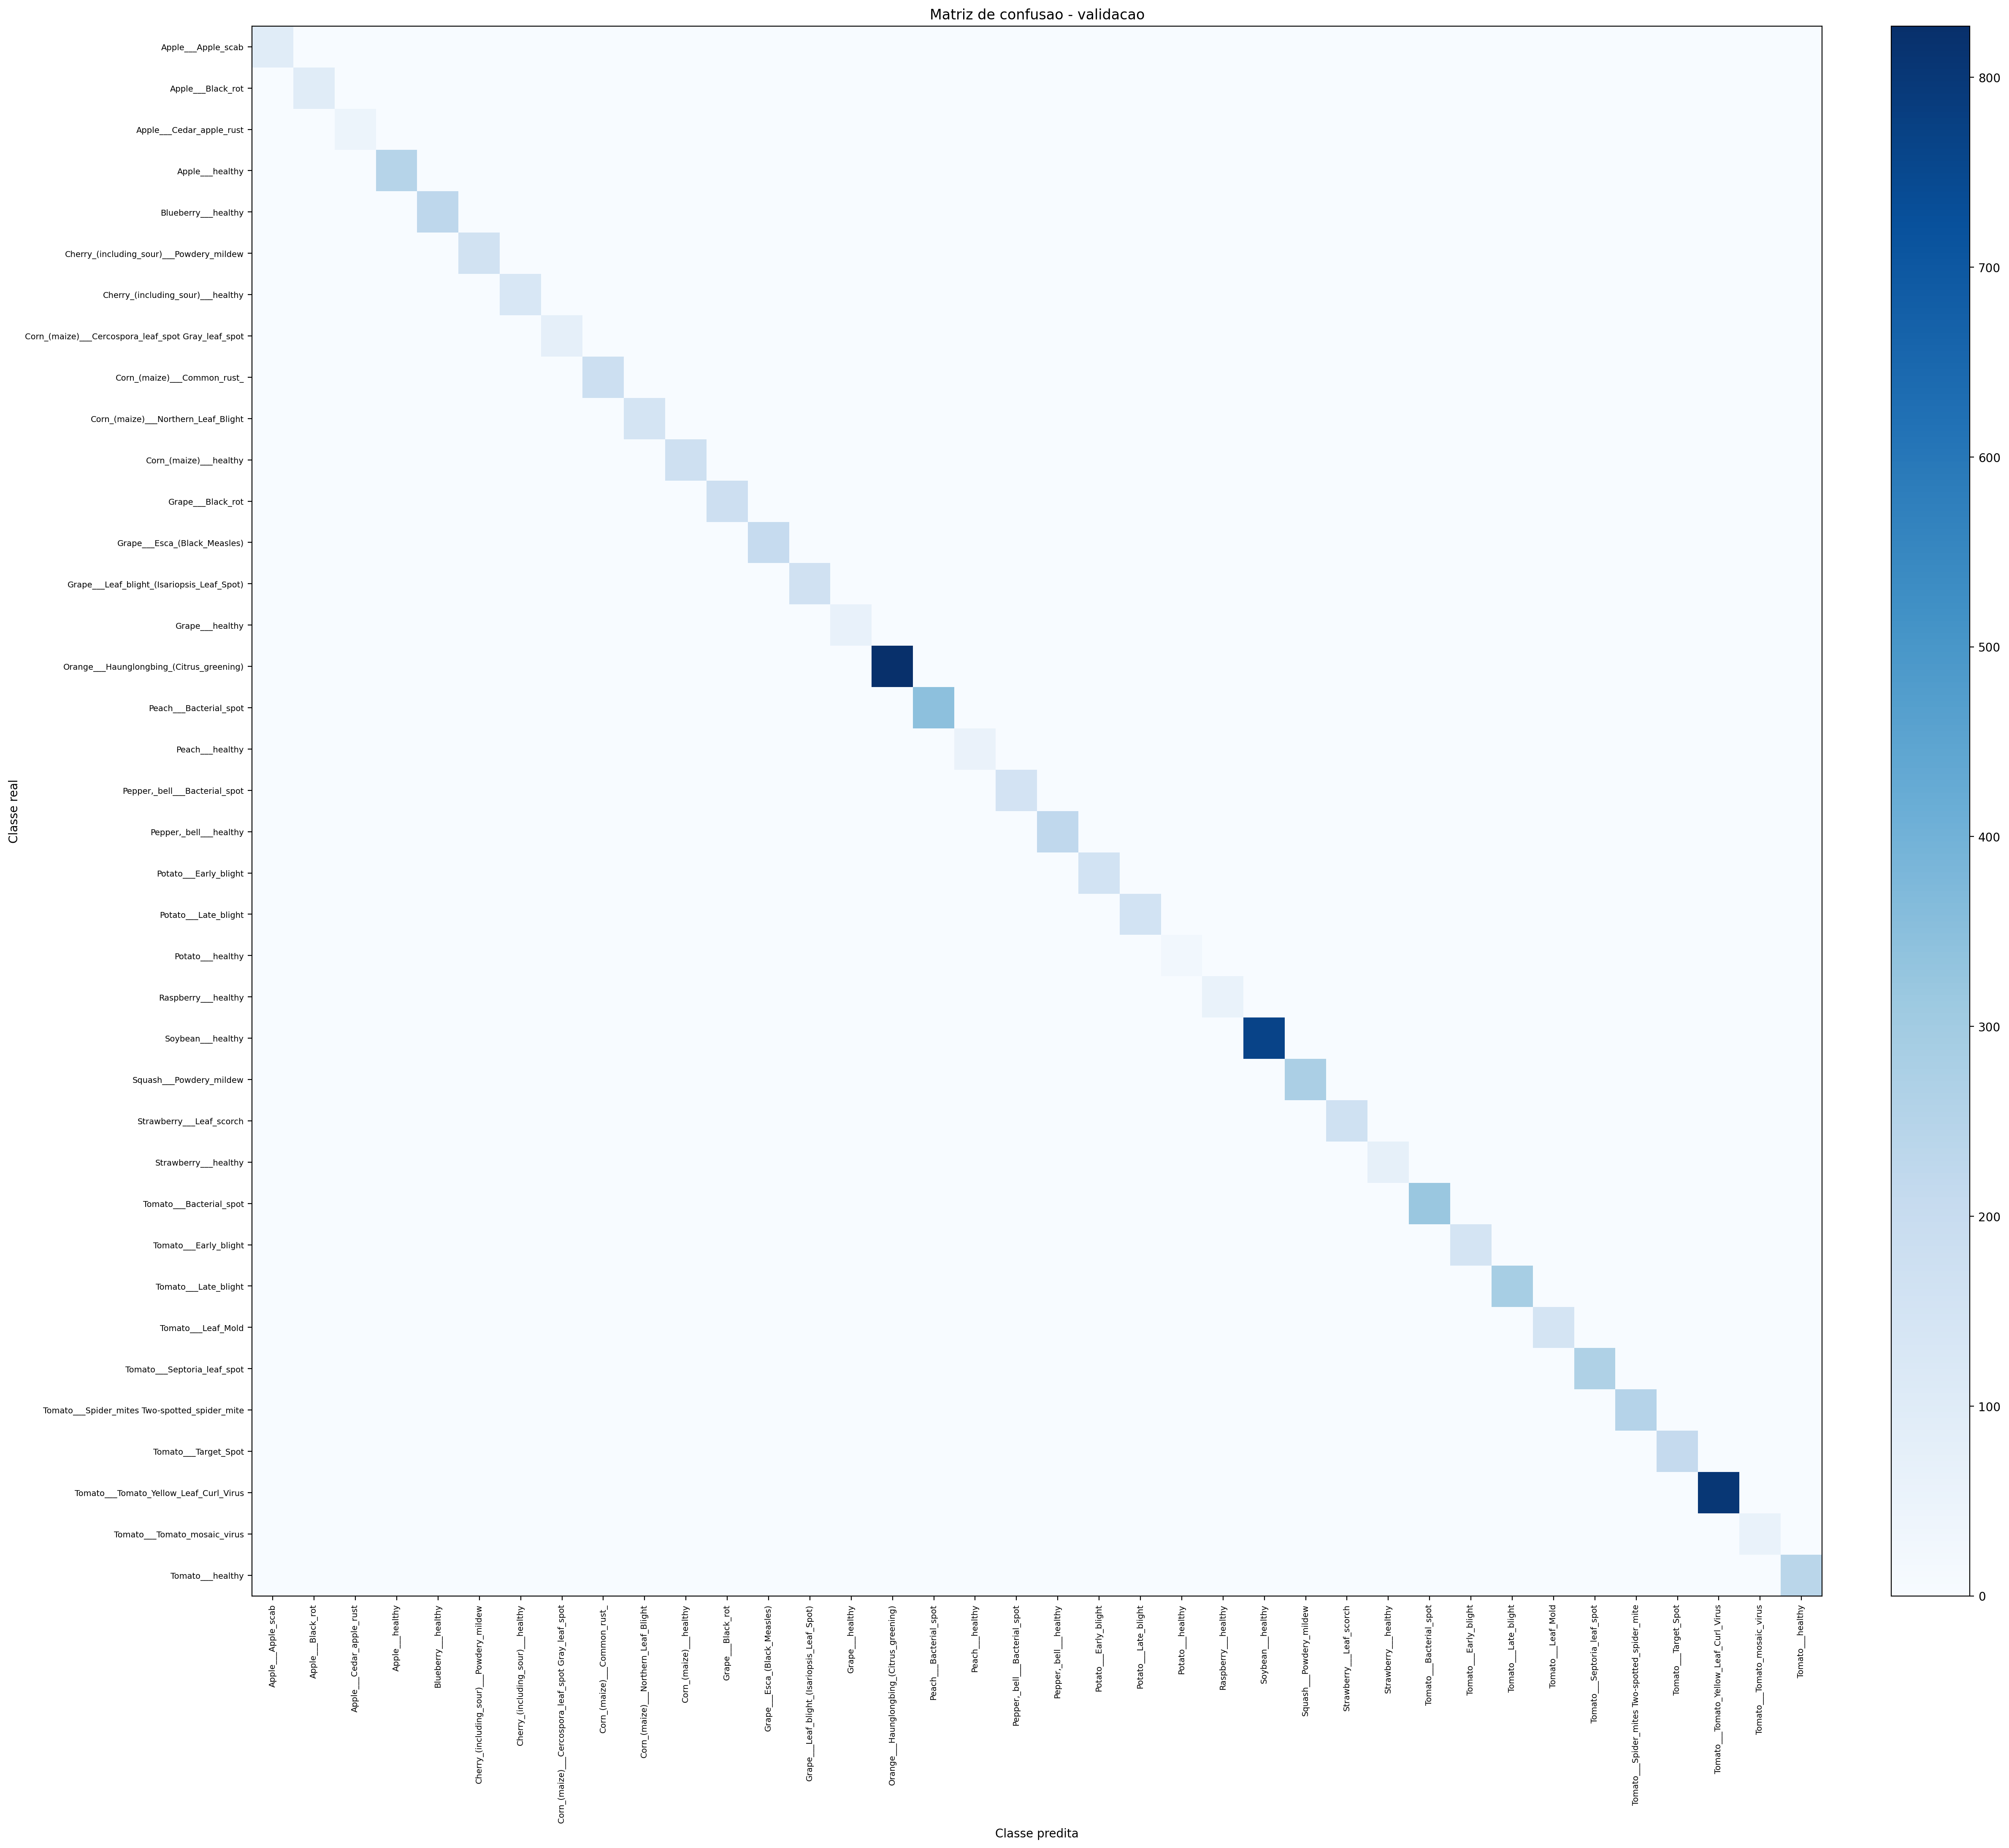

In [12]:
confusion_matrix_path = EFFICIENTNET_RESULTS_DIR / 'validation_confusion_matrix.png'
display(Image(filename=str(confusion_matrix_path), width=1100))

## Artefatos gerados

In [13]:
artifacts = sorted(path for path in EFFICIENTNET_RESULTS_DIR.iterdir() if path.is_file())
display(pd.DataFrame({
    'arquivo': [path.name for path in artifacts],
    'caminho': [str(path) for path in artifacts],
    'tamanho_bytes': [path.stat().st_size for path in artifacts],
}))
with (EFFICIENTNET_RESULTS_DIR / 'experiment_metadata.json').open(encoding='utf-8') as file:
    experiment_metadata = json.load(file)
display(pd.Series(experiment_metadata, name='experiment_metadata').to_frame())
print('Todos os resultados da EfficientNet-B0 estão em:', EFFICIENTNET_RESULTS_DIR)

,arquivo,caminho,tamanho_bytes
0,architecture_summary.json,/content/drive/MyDrive/plant-disease-classific...,2923
1,efficientnet_b0_best.pth,/content/drive/MyDrive/plant-disease-classific...,49147450
2,efficientnet_b0_history.csv,/content/drive/MyDrive/plant-disease-classific...,2519
3,experiment_metadata.json,/content/drive/MyDrive/plant-disease-classific...,2545
4,timing_summary.json,/content/drive/MyDrive/plant-disease-classific...,655
5,validation_confusion_matrix.png,/content/drive/MyDrive/plant-disease-classific...,505671
6,validation_metrics.csv,/content/drive/MyDrive/plant-disease-classific...,260
7,validation_metrics_by_class.csv,/content/drive/MyDrive/plant-disease-classific...,2587


,experiment_metadata
execution_timestamp,2026-10-21T04:44:58.420075+00:00
operating_system,Linux
platform,Linux-6.6.122+-x86_64-with-glibc2.39
python_version,"3.13.15 (main, Aug 6 2026, 11:06:22) [GCC 13...."
pytorch_version,2.11.0+cu130
torchvision_version,0.26.0+cu130
cuda_available,True
pytorch_cuda_version,13.0
selected_device,cuda
gpu_name,NVIDIA L4


Todos os resultados da EfficientNet-B0 estão em: /content/drive/MyDrive/plant-disease-classification/results/efficientnet_b0
